# Sections 3.5 and 3.6: K-means and Support Vector Machines
**Topics:** K-means, Support vector machine

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/drive/11u4UQhwy-BKKd47IJ3U98VMYMgmYITUv?usp=sharing)


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs, make_classification
from sklearn.cluster import KMeans
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

np.set_printoptions(precision=4, suppress=True)


## K-means

K-means uses clustered data to group similar labeled data together, forming groups of data that can be used for further analysis. In this case, we show how cluster centers and k-means clustering works for 10000 samples with 7 different clusters.

Cluster centers:
[[-6.2344  4.0205]
 [ 9.5772  0.7535]
 [-5.1229 -2.1279]
 [-6.0036  5.1251]
 [ 9.0148  1.6366]
 [-4.9779 -3.1542]
 [-7.1526  4.7767]]
Inertia: 5093.181136511723


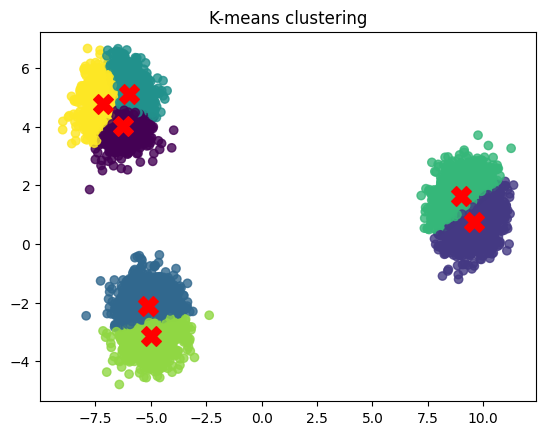

In [2]:
X, true_labels = make_blobs(n_samples=10000, centers=3, cluster_std=0.65, random_state=422)
kmeans = KMeans(n_clusters=7, n_init=20, random_state=422)
cluster_labels = kmeans.fit_predict(X)

print("Cluster centers:")
print(kmeans.cluster_centers_)
print("Inertia:", kmeans.inertia_)

plt.scatter(X[:,0], X[:,1], c=cluster_labels, cmap="viridis", alpha=0.8)
plt.scatter(kmeans.cluster_centers_[:,0], kmeans.cluster_centers_[:,1], marker="X", s=200, color="red")
plt.title("K-means clustering")
plt.show()


## Support vector machine
Support Vector Machines (SVMs) use training data points called support vectors to distinguish classes. The distinguishing lines or planes that separate these classes are called hyperplanes, which segmentate training data for better accuracy and precision. In this case, we demonstrate how a SVM works for 10K samples, 12 features, and 12 classes.

Training accuracy: 0.992
Number of support vectors: [159 159]


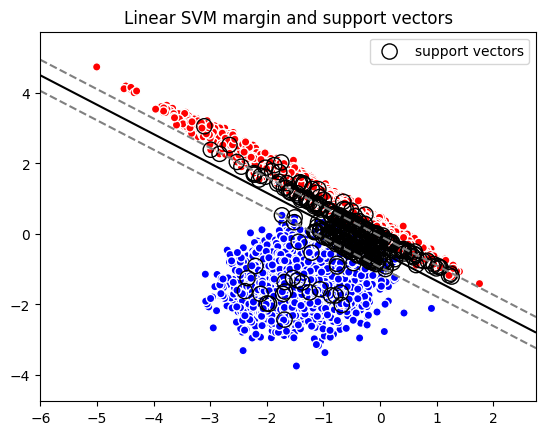

In [4]:
Xc, yc = make_classification(n_samples=10000, n_features=2, n_redundant=0, n_informative=2, n_classes=2,
                             n_clusters_per_class=1, class_sep=1.3, random_state=422)
svm = SVC(kernel="linear", C=1.0)
svm.fit(Xc, yc)
pred = svm.predict(Xc)

print("Training accuracy:", accuracy_score(yc, pred))
print("Number of support vectors:", svm.n_support_)

xx, yy = np.meshgrid(np.linspace(Xc[:,0].min()-1, Xc[:,0].max()+1, 150),
                     np.linspace(Xc[:,1].min()-1, Xc[:,1].max()+1, 150))
Z = svm.decision_function(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

plt.contour(xx, yy, Z, levels=[-1, 0, 1], colors=["gray", "black", "gray"], linestyles=["--", "-", "--"])
plt.scatter(Xc[:,0], Xc[:,1], c=yc, cmap="bwr", edgecolor="white")
plt.scatter(svm.support_vectors_[:,0], svm.support_vectors_[:,1], s=120, facecolors="none", edgecolors="black", label="support vectors")
plt.title("Linear SVM margin and support vectors")
plt.legend()
plt.show()